In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from functools import partial
from jcamp import readfile
from kafe2 import XYFit
import pickle
import yaml

In [2]:
from setup import (
    gray,
    black,
    colors,
    plot_style,
    filepath,
    calibration_labels,
    spectral_range,
    absorption_path_length,
    calibration_settling_time as settling_time,
    calibration_type,
)
from processing import (
    is_system_settled,
    center_spectra,
    broaden_spectrum,
    concentration_from_flowrate,
    voltage_from_concentration,
    concentration_from_voltage,
    scaling_from_pid_to_cell,
    scaling_from_cell_to_pid,
)

In [3]:
plt.style.use(plot_style)

### Load calibration datasets

In [4]:
times = []
voltages = []
absorbances = []
flowrates = []
setpoints = []
concentrations_pid_readout = []
are_settled = []
are_analyte_free = []

wavenumber = None
spectral_resolution = None
gas_1 = None
gas_2 = None
split_ratio = None
window_type = None
correction_type = None
signal_type = None

for label in calibration_labels:
    dataset = np.load(filepath / f"{label}.npz")
    metadata = yaml.safe_load((filepath / f"{label}.yaml").read_text())

    if spectral_resolution is None:
        spectral_resolution = metadata["sampling"]["spectral_resolution"]
    elif spectral_resolution != metadata["sampling"]["spectral_resolution"]:
        raise ValueError(f"Spectral resolution mismatch for {label}.")

    time = dataset["time"]
    spectrum = dataset["spectrum"]

    if wavenumber is None:
        wavenumber = dataset["wavenumber"]
        spectral_mask = (wavenumber >= spectral_range[0]) & (
            wavenumber <= spectral_range[1]
        )
    elif wavenumber.shape != dataset["wavenumber"].shape:
        raise ValueError(f"Wavenumber mismatch for {label}.")
    elif not np.allclose(wavenumber, dataset["wavenumber"], atol=1e-3):
        raise ValueError(f"Wavenumber mismatch for {label}.")

    if gas_1 is None:
        gas_1 = str(dataset["gas_1"])
    elif gas_1 != str(dataset["gas_1"]):
        raise ValueError(f"Gas 1 mismatch for {label}.")

    if gas_2 is None:
        gas_2 = str(dataset["gas_2"])
    elif gas_2 != str(dataset["gas_2"]):
        raise ValueError(f"Gas 2 mismatch for {label}.")

    if split_ratio is None:
        split_ratio = float(dataset["split_ratio"])
    elif split_ratio != float(dataset["split_ratio"]):
        raise ValueError(f"Split ratio mismatch for {label}.")

    if dataset["type"] == "twins":
        if window_type is None:
            window_type = str(dataset["window_type"])
        elif window_type != str(dataset["window_type"]):
            raise ValueError(f"Window type mismatch for {label}.")

        if correction_type is None:
            correction_type = str(dataset["correction_type"])
        elif correction_type != str(dataset["correction_type"]):
            raise ValueError(f"Correction type mismatch for {label}.")

        if signal_type is None:
            signal_type = str(dataset["signal_type"])
        elif signal_type != str(dataset["signal_type"]):
            raise ValueError(f"Signal type mismatch for {label}.")

    setpoint_0 = dataset["setpoint_0"]
    setpoint_1 = dataset["setpoint_1"]
    setpoint_2 = dataset["setpoint_2"]
    setpoint = np.stack(
        [
            np.mean(setpoint_0, axis=1),
            np.mean(setpoint_1, axis=1),
            np.mean(setpoint_2, axis=1),
        ],
        axis=1,
    )

    if np.any(np.sum(np.round(setpoint[:, 1:], 3) > 0, axis=1) > 1):
        raise ValueError(f"Setpoints can't be both non-zero for {label}.")

    flowrate_0 = dataset["flowrate_0"]
    flowrate_1 = dataset["flowrate_1"]
    flowrate_2 = dataset["flowrate_2"]
    flowrate = np.stack(
        [
            np.mean(flowrate_0, axis=1),
            np.mean(flowrate_1, axis=1),
            np.mean(flowrate_2, axis=1),
        ],
        axis=1,
    )

    voltage_pid_1 = dataset["voltage_pid_1"] / 1e6  # (V)
    voltage_pid_2 = dataset["voltage_pid_2"] / 1e6  # (V)
    voltage = np.stack(
        [np.mean(voltage_pid_1, axis=1), np.mean(voltage_pid_2, axis=1)],
        axis=1,
    )

    concentration_gas_1 = dataset["concentration_gas_1"]
    concentration_gas_2 = dataset["concentration_gas_2"]
    concentration_pid_readout = np.stack(
        [np.mean(concentration_gas_1, axis=1), np.mean(concentration_gas_2, axis=1)],
        axis=1,
    )

    time_offset = np.max(np.concatenate(times)) if times else 0
    time = np.min(time, axis=1) + time_offset

    spectrum = spectrum[:, spectral_mask]

    is_settled = is_system_settled(time, setpoint_1, setpoint_2, settling_time)
    is_analyte_free = (
        np.all((setpoint_0 != 0) & (setpoint_1 == 0) & (setpoint_2 == 0), axis=1)
        & is_settled
    )

    if not np.any(is_analyte_free):
        raise ValueError(f"No analyte-free spectra found for {label}.")

    absorbance = -np.log10(spectrum / np.mean(spectrum[is_analyte_free, :], axis=0))

    times.append(time)
    voltages.append(voltage)
    absorbances.append(absorbance)
    flowrates.append(flowrate)
    setpoints.append(setpoint)
    concentrations_pid_readout.append(concentration_pid_readout)
    are_settled.append(is_settled)
    are_analyte_free.append(is_analyte_free)

times = np.concatenate(times, axis=0)
voltages = np.concatenate(voltages, axis=0)
absorbances = np.concatenate(absorbances, axis=0)
flowrates = np.concatenate(flowrates, axis=0)
setpoints = np.concatenate(setpoints, axis=0)
concentrations_pid_readout = np.concatenate(concentrations_pid_readout, axis=0)
are_settled = np.concatenate(are_settled, axis=0)
are_analyte_free = np.concatenate(are_analyte_free, axis=0)

gases = (gas_1, gas_2)
wavenumber = wavenumber[spectral_mask]

In [5]:
number_spectra, number_wavenumbers = np.shape(absorbances)
number_gases = len(gases)

print(f"Datasets: {', '.join(calibration_labels)}")
print(f"Gases: {gas_1.capitalize()}, {gas_2.capitalize()}")
print(
    f"Spectra: {number_spectra} "
    f"({np.sum(are_settled)} are settled, {np.sum(are_analyte_free)} are analyte free)"
)
print(f"Wavenumbers: {number_wavenumbers} at {spectral_resolution} cm^-1 resolution")

Datasets: GRASP26_62F
Gases: Isopropanol, Ethanol
Spectra: 209 (109 are settled, 59 are analyte free)
Wavenumbers: 30 at 20 cm^-1 resolution


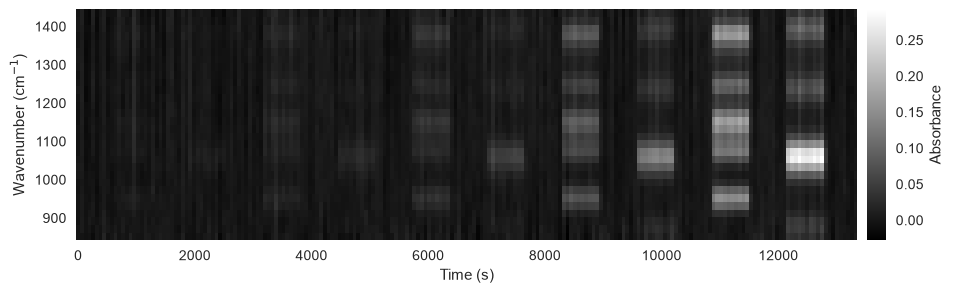

In [6]:
fig, ax = plt.subplots(figsize=(12, 3))

mesh = ax.pcolormesh(
    times,
    wavenumber,
    absorbances.T,
    cmap="gray",
)

ax.set_xlabel("Time (s)")
ax.set_ylabel("Wavenumber (cm$^{-1}$)")

fig.colorbar(mesh, ax=ax, label="Absorbance", aspect=12, pad=0.01)

### Estimate concentrations from NIST spectra

In [7]:
wavenumber_nist = {}
absorption_coefficients_nist = {}
for gas in gases:
    data_nist = readfile(Path("NIST", f"{gas}.jdx"))

    if data_nist["yunits"] == "TRANSMITTANCE":
        data_nist["y"] = -np.log10(data_nist["y"])

    wavenumber_nist[gas] = data_nist["x"]
    absorption_coefficients_nist[gas] = broaden_spectrum(
        data_nist["x"],
        data_nist["y"],
        spectral_range,
        spectral_resolution,
        window_type,
    )

    spectral_mask_nist = (wavenumber_nist[gas] >= spectral_range[0]) & (
        wavenumber_nist[gas] <= spectral_range[1]
    )
    wavenumber_nist[gas] = wavenumber_nist[gas][spectral_mask_nist]
    absorption_coefficients_nist[gas] = absorption_coefficients_nist[gas][
        spectral_mask_nist
    ]

In [8]:
absorption_coefficients = []
for gas in gases:
    absorption_coefficients.append(
        np.interp(wavenumber, wavenumber_nist[gas], absorption_coefficients_nist[gas])
    )

absorption_coefficients = np.stack(absorption_coefficients, axis=1)

absorbances_centered = center_spectra(absorbances)
absorption_coefficients_centered = center_spectra(absorption_coefficients.T).T

concentrations_nist, *_ = np.linalg.lstsq(
    absorption_coefficients_centered * absorption_path_length,
    absorbances_centered.T,
    rcond=None,
)

concentrations_nist = concentrations_nist.T

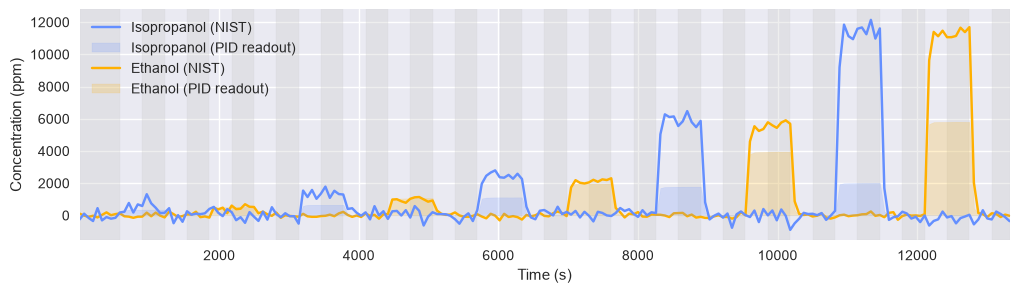

In [9]:
fig, ax = plt.subplots(figsize=(12, 3))

for ii, gas in enumerate(gases):
    ax.plot(
        times,
        concentrations_nist[:, ii],
        color=colors[ii],
        label=f"{gas.capitalize()} (NIST)",
        zorder=25 - 10 * ii,
    )
    ax.fill_between(
        times,
        concentrations_pid_readout[:, ii],
        color=colors[ii] + "33",
        label=f"{gas.capitalize()} (PID readout)",
        zorder=20 - 10 * ii,
    )

switch_indices = np.flatnonzero(np.diff(are_settled))
settled_interval_edges = np.concatenate(([0], switch_indices, [len(are_settled) - 1]))
for ii in range(0, len(settled_interval_edges) - 1, 2):
    ax.axvspan(
        times[settled_interval_edges[ii]],
        times[settled_interval_edges[ii + 1]],
        color=gray + "55",
        zorder=5,
    )

ax.set_xlabel("Time (s)")
ax.set_ylabel("Concentration (ppm)")
ax.margins(x=0)
ax.legend()

### Calibrate sensor response

Isopropanol: characteristic concentration = 5832 ppm, cutoff concentration = 10713 ppm, baseline voltage = 0.062 V, saturation voltage = 0.748 V, fitted levels = 5 of 6
Ethanol: characteristic concentration = 10673 ppm, cutoff concentration = 18980 ppm, baseline voltage = 0.056 V, saturation voltage = 0.722 V, fitted levels = 6 of 6


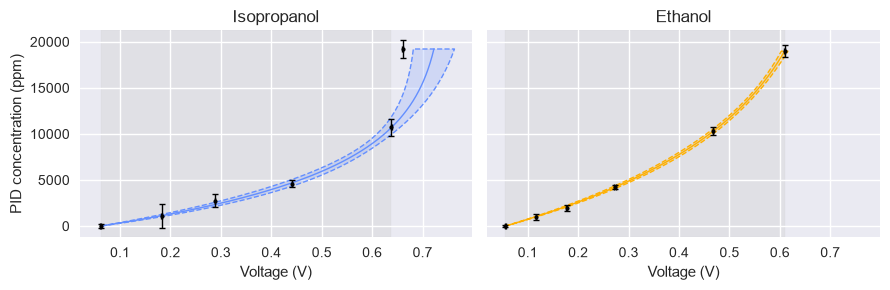

In [10]:
fig, axs = plt.subplots(
    1,
    number_gases,
    figsize=(4.5 * number_gases, 3),
    sharex=True,
    sharey=True,
    squeeze=False,
)

are_flowing = np.round(setpoints[:, 1:], 3) > 0

characteristic_concentrations = []
baseline_voltages = []
saturation_voltages = []
cutoff_concentrations = []
concentration_estimators_pid = []
for ii, gas in enumerate(gases):
    calibration_mask = are_settled & (are_flowing[:, ii] | ~are_flowing.any(axis=1))

    scaling_cell_to_pid = scaling_from_cell_to_pid(flowrates, split_ratio, ii + 1)

    response_statistics = pd.DataFrame(
        {
            "setpoint": np.round(setpoints[calibration_mask, ii + 1], 3),
            "voltages": voltages[calibration_mask, ii],
            "concentrations": scaling_cell_to_pid[calibration_mask]
            * concentrations_nist[calibration_mask, ii],
        }
    )

    response_statistics = response_statistics.groupby("setpoint").agg(
        concentrations_mean=("concentrations", "mean"),
        concentrations_sigma=(
            "concentrations",
            lambda c: c.std(ddof=1) / np.sqrt(len(c)),
        ),
        voltages_mean=("voltages", "mean"),
        voltages_sigma=("voltages", lambda v: v.std(ddof=1) / np.sqrt(len(v))),
    )

    response_statistics_selected = response_statistics

    is_success = False
    while not is_success:
        voltage_minimum = response_statistics_selected["voltages_mean"].min()
        voltage_maximum = response_statistics_selected["voltages_mean"].max()
        concentration_maximum = response_statistics_selected[
            "concentrations_mean"
        ].max()

        response_fit = XYFit(
            xy_data=[
                response_statistics_selected["concentrations_mean"],
                response_statistics_selected["voltages_mean"],
            ],
            model_function=voltage_from_concentration,
        )
        response_fit.add_error(
            axis="x", err_val=response_statistics_selected["concentrations_sigma"]
        )
        response_fit.add_error(
            axis="y", err_val=response_statistics_selected["voltages_sigma"]
        )

        response_fit.set_parameter_values(
            characteristic_concentration=concentration_maximum,
            baseline_voltage=voltage_minimum,
            saturation_voltage=voltage_maximum,
        )
        response_fit.limit_parameter("characteristic_concentration", lower=0, upper=1e6)
        response_fit.fix_parameter("baseline_voltage", voltage_minimum)
        response_fit.limit_parameter(
            "saturation_voltage", lower=voltage_maximum, upper=10
        )

        response_fit.do_fit()

        if response_fit.chi2_probability < 0.1:
            response_statistics_selected = response_statistics_selected.drop(
                index=response_statistics_selected["voltages_mean"].idxmax()
            )
        else:
            is_success = True

    characteristic_concentration, baseline_voltage, saturation_voltage = (
        response_fit.parameter_values
    )

    characteristic_concentrations.append(characteristic_concentration)
    baseline_voltages.append(baseline_voltage)
    saturation_voltages.append(saturation_voltage)

    index = response_statistics_selected["concentrations_mean"].idxmax()
    cutoff_concentration = response_statistics_selected.loc[
        index, "concentrations_mean"
    ]
    cutoff_concentrations.append(cutoff_concentration)

    concentrations_fit = np.linspace(
        0, response_statistics["concentrations_mean"].max(), 1001
    )
    voltages_fit = response_fit.eval_model_function(x=concentrations_fit)
    voltages_fit_sigma = response_fit.error_band(concentrations_fit)

    axs[0, ii].axvspan(
        voltage_minimum,
        voltage_maximum,
        color=gray + "55",
        zorder=0,
    )
    axs[0, ii].errorbar(
        response_statistics["voltages_mean"],
        response_statistics["concentrations_mean"],
        xerr=3 * response_statistics["voltages_sigma"],
        yerr=3 * response_statistics["concentrations_sigma"],
        linewidth=1,
        color=black,
        ecolor=black,
        fmt="o",
        markersize=3,
        capsize=2,
        capthick=1,
        zorder=10,
    )
    axs[0, ii].plot(
        voltages_fit,
        concentrations_fit,
        color=colors[ii],
        linewidth=1,
        zorder=5,
    )
    axs[0, ii].fill_betweenx(
        concentrations_fit,
        voltages_fit - 3 * voltages_fit_sigma,
        voltages_fit + 3 * voltages_fit_sigma,
        edgecolor=colors[ii],
        facecolor=colors[ii] + "33",
        linewidth=1,
        linestyle="--",
        zorder=5,
    )

    axs[0, ii].set_xlabel("Voltage (V)")
    axs[0, ii].set_title(gas.capitalize())

    concentration_estimators_pid.append(
        partial(
            concentration_from_voltage,
            characteristic_concentration=characteristic_concentration,
            baseline_voltage=baseline_voltage,
            saturation_voltage=saturation_voltage,
        )
    )

    print(
        f"{gas.capitalize()}: "
        f"characteristic concentration = {characteristic_concentration:.0f} ppm, "
        f"cutoff concentration = {cutoff_concentration:.0f} ppm, "
        f"baseline voltage = {baseline_voltage:.3f} V, "
        f"saturation voltage = {saturation_voltage:.3f} V, "
        f"fitted levels = {len(response_statistics_selected)} "
        f"of {len(response_statistics)}"
    )

axs[0, 0].set_ylabel("PID concentration (ppm)")

fig.tight_layout()

In [11]:
concentration_estimators_flowrate = []
for ii, gas in enumerate(gases):
    coefficients, *_ = np.linalg.lstsq(
        np.atleast_2d(flowrates[are_settled, ii + 1]).T,
        concentrations_nist[are_settled, ii].T,
        rcond=None,
    )
    concentration_per_flowrate = coefficients[0]

    concentration_estimators_flowrate.append(
        partial(
            concentration_from_flowrate,
            concentration_per_flowrate=concentration_per_flowrate,
        )
    )

    print(f"{gas.capitalize()}: {concentration_per_flowrate:.1f} ppm per ml/min")

Isopropanol: 116.1 ppm per ml/min
Ethanol: 113.6 ppm per ml/min


In [12]:
concentrations_pid = np.zeros_like(concentrations_nist)
concentrations_flowrate = np.zeros_like(concentrations_nist)
for ii in range(number_gases):
    scaling_pid_to_cell = scaling_from_pid_to_cell(flowrates, split_ratio, ii + 1)

    concentrations_pid[:, ii] = scaling_pid_to_cell * (
        concentration_estimators_pid[ii](voltages[:, ii])
    )
    concentrations_flowrate[:, ii] = concentration_estimators_flowrate[ii](
        flowrates[:, ii + 1]
    )

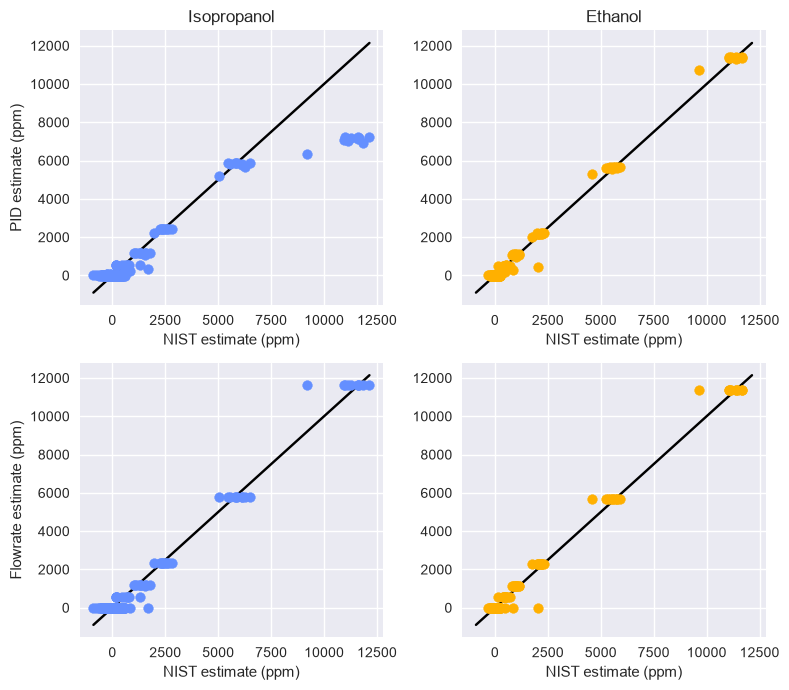

In [13]:
fig, axs = plt.subplots(
    2,
    number_gases,
    figsize=(4 * number_gases, 7),
    squeeze=False,
)

for ii, gas in enumerate(gases):
    axs[0, ii].scatter(
        concentrations_nist[:, ii],
        concentrations_pid[:, ii],
        color=colors[ii],
        zorder=10,
    )
    axs[1, ii].scatter(
        concentrations_nist[:, ii],
        concentrations_flowrate[:, ii],
        color=colors[ii],
        zorder=10,
    )

    axs[0, ii].set_title(gas.capitalize())

for ax in axs.ravel():
    ax.plot(
        [concentrations_nist.min(), concentrations_nist.max()],
        [concentrations_nist.min(), concentrations_nist.max()],
        color=black,
        zorder=5,
    )

    ax.set_xlabel("NIST estimate (ppm)")

axs[0, 0].set_ylabel("PID estimate (ppm)")
axs[1, 0].set_ylabel("Flowrate estimate (ppm)")

fig.tight_layout()

In [14]:
for ii, gas in enumerate(gases):
    path = Path("models", f"estimator-{gas.lower()}.pkl")

    with open(path, "wb") as file:
        if calibration_type == "flowrate":
            pickle.dump(
                {
                    "estimator": concentration_estimators_flowrate[ii],
                },
                file,
            )
        elif calibration_type == "pid":
            pickle.dump(
                {
                    "estimator": concentration_estimators_pid[ii],
                    "characteristic_concentration": characteristic_concentrations[ii],
                    "baseline_voltage": baseline_voltages[ii],
                    "saturation_voltage": saturation_voltages[ii],
                    "cutoff_concentration": cutoff_concentrations[ii],
                },
                file,
            )

    print(f"Saved: {path}")

Saved: models\estimator-isopropanol.pkl
Saved: models\estimator-ethanol.pkl
